# WoFS/WoFSCast verification-suite tutorial

Walks through `py_obj_plotting`'s full matching-output verification suite -- POD/FAR/FBIAS/CSI time series, matched-pair diagnostic-property distributions, performance diagrams, and object-property POD heatmaps -- against a small, real, bundled subset of WoFS and WoFSCast forecasts matched to MRMS truth.

`sample_data/wofs_wofscast_case/` bundles exactly 4 real match files (~880 KB total): 2 real forecast cases (2026-05-08 00Z and 01Z), each for WoFS and for WoFSCast, both real 18-member ensembles spanning 0-6h. Every file was confirmed to contain all 5 real match categories (hit/miss/false_alarm/truth_extra/forecast_extra) before bundling.

This is a **deliberately small 2-case slice** chosen to be runnable and committable, not a statistically meaningful sample -- the performance diagrams below have exactly 2 points, and some plots (e.g. per-storm-mode metrics for rarer modes) will show few or zero records for one or both systems. `configs/config_sfe_wofs_vs_wofscast_suite.yaml` demonstrates the identical capability against the much larger, non-bundled `sfe_poster/` archive (207+ real cases).


In [1]:
import os
import sys

REPO_ROOT = os.path.abspath(os.path.join(os.getcwd(), "..", ".."))
if REPO_ROOT not in sys.path:
    sys.path.insert(0, REPO_ROOT)

from IPython.display import Image, display

from py_obj_plotting.drivers.plot_matching_timeseries import run_one_case

CONFIG_PATH = "../configs/config_sample_wofs_wofscast_suite.yaml"


## Run the full suite

One call runs everything the config asks for: POD/FAR/FBIAS/CSI time series, matched-pair diagnostic distributions, object count/area series, case-scatter and lead-time-trajectory performance diagrams, two-system CSI-difference diagnostics (diagram + POD/FAR/FBIAS/CSI difference histograms), object-property POD heatmaps (+ two-system difference), and the same bundle repeated per storm mode.


In [2]:
result = run_one_case(CONFIG_PATH)
print(f"Wrote {len(result['written_paths'])} image(s) to {result['config'].output_dir}")
print(f"Shared forecast cases: {len(result['case_report'].shared_cases)}")


Systems: ['WoFS', 'WoFSCast']
Shared forecast cases: 2/2

Building multi-system match climatology (lead_time_mode='union')...
  WoFS: 73 lead time(s), members=['mem00', 'mem01', 'mem02', 'mem03', 'mem04', 'mem05', 'mem06', 'mem07', 'mem08', 'mem09', 'mem10', 'mem11', 'mem12', 'mem13', 'mem14', 'mem15', 'mem16', 'mem17']
  WoFSCast: 35 lead time(s), members=['mem00', 'mem01', 'mem02', 'mem03', 'mem04', 'mem05', 'mem06', 'mem07', 'mem08', 'mem09', 'mem10', 'mem11', 'mem12', 'mem13', 'mem14', 'mem15', 'mem16', 'mem17']

Computing verification stats (POD/FAR/FBIAS/CSI, 95% bootstrap CI)...


Building multi-system diagnostic-distribution climatology...
Building multi-system object-stats climatology...



Building storm-mode-filtered match climatologies (modes=['cellular', 'mixed', 'linear'])...
  WoFS (cellular): 2972 total hit/miss/false_alarm record(s)
  WoFSCast (cellular): 926 total hit/miss/false_alarm record(s)


  WoFS (cellular) diagnostic hit-pairs: 711
  WoFSCast (cellular) diagnostic hit-pairs: 134


  WoFS (cellular) objects: 2651 forecast, 71 truth (MRMS)
  WoFSCast (cellular) objects: 593 forecast, 71 truth (MRMS)


  WoFS (mixed): 5 total hit/miss/false_alarm record(s)
  WoFSCast (mixed): 0 total hit/miss/false_alarm record(s)


... (8 outputs left out)

  diff histograms (0-60min): 2 matched case(s)


  diff histograms (180-240min): 2 matched case(s)

Building object-property POD climatologies (properties=['area', 'max_intensity', 'age'])...
  WoFS [area]: 1256 hit/miss record(s) with real data
  WoFS [max_intensity]: 1256 hit/miss record(s) with real data
  WoFS [age]: 0 hit/miss record(s) with real data (tracking likely wasn't enabled for the truth series)
  WoFSCast [area]: 480 hit/miss record(s) with real data
  WoFSCast [max_intensity]: 480 hit/miss record(s) with real data
  WoFSCast [age]: 0 hit/miss record(s) with real data (tracking likely wasn't enabled for the truth series)


  skipping heatmap_age_WoFS.png -- no real 'age' data for 'WoFS'
  skipping heatmap_age_WoFSCast.png -- no real 'age' data for 'WoFSCast'


  skipping heatmap_age_diff.png -- insufficient 'age' data (WoFS=0, WoFSCast=0)

wrote /Users/asdf/Documents/work/2026_analysis/2026_ncar_verif/py_obj_plotting/configs/output/sample_wofs_wofscast_suite/pod_comparison.png
wrote /Users/asdf/Documents/work/2026_analysis/2026_ncar_verif/py_obj_plotting/configs/output/sample_wofs_wofscast_suite/far_comparison.png
wrote /Users/asdf/Documents/work/2026_analysis/2026_ncar_verif/py_obj_plotting/configs/output/sample_wofs_wofscast_suite/fbias_comparison.png
wrote /Users/asdf/Documents/work/2026_analysis/2026_ncar_verif/py_obj_plotting/configs/output/sample_wofs_wofscast_suite/csi_comparison.png
wrote /Users/asdf/Documents/work/2026_analysis/2026_ncar_verif/py_obj_plotting/configs/output/sample_wofs_wofscast_suite/area_ratio_comparison.png
wrote /Users/asdf/Documents/work/2026_analysis/2026_ncar_verif/py_obj_plotting/configs/output/sample_wofs_wofscast_suite/max_intensity_diff_comparison.png
wrote /Users/asdf/Documents/work/2026_analysis/2026_nca

## Time series -- POD vs. lead hour

Both systems' ensemble-mean POD (thick line) with individual-member lines (thin, semi-transparent) and a shaded bootstrap-CI band.


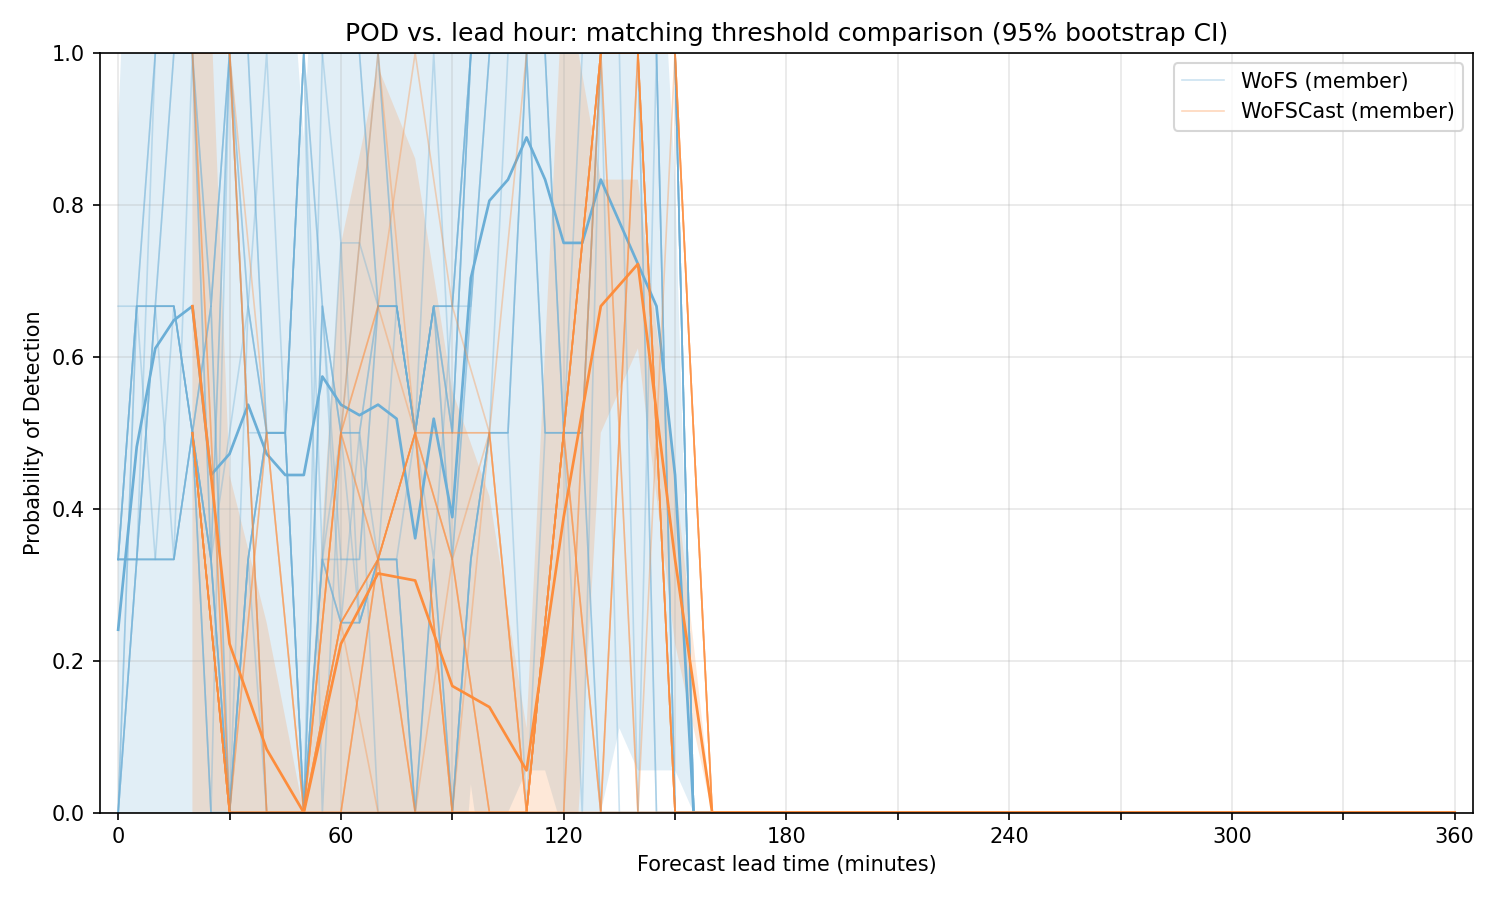

In [3]:
display(Image(filename=os.path.join(result["config"].output_dir, "pod_comparison.png")))


## Matched-pair diagnostic distribution -- centroid distance

For hit pairs only: the interquartile-range shaded band + median line of forecast-vs-truth centroid distance, per lead hour.


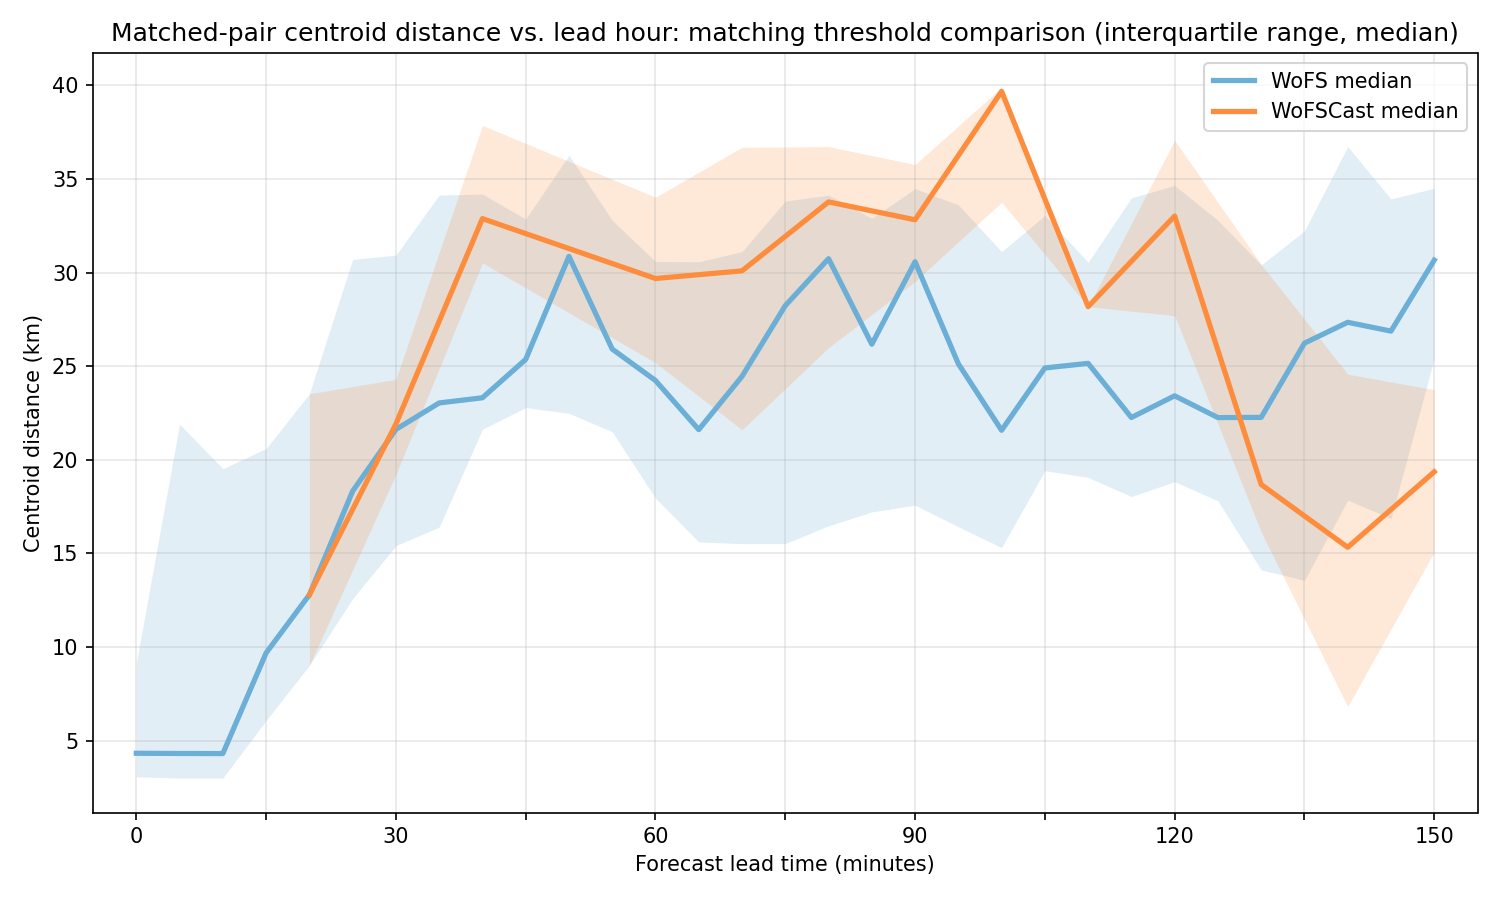

In [4]:
display(Image(filename=os.path.join(result["config"].output_dir, "centroid_dist_comparison.png")))


## Performance diagram -- case scatter (0-60 min)

One marker per real forecast case (only 2 here), positioned by Success Ratio vs. POD, sized by truth object count.


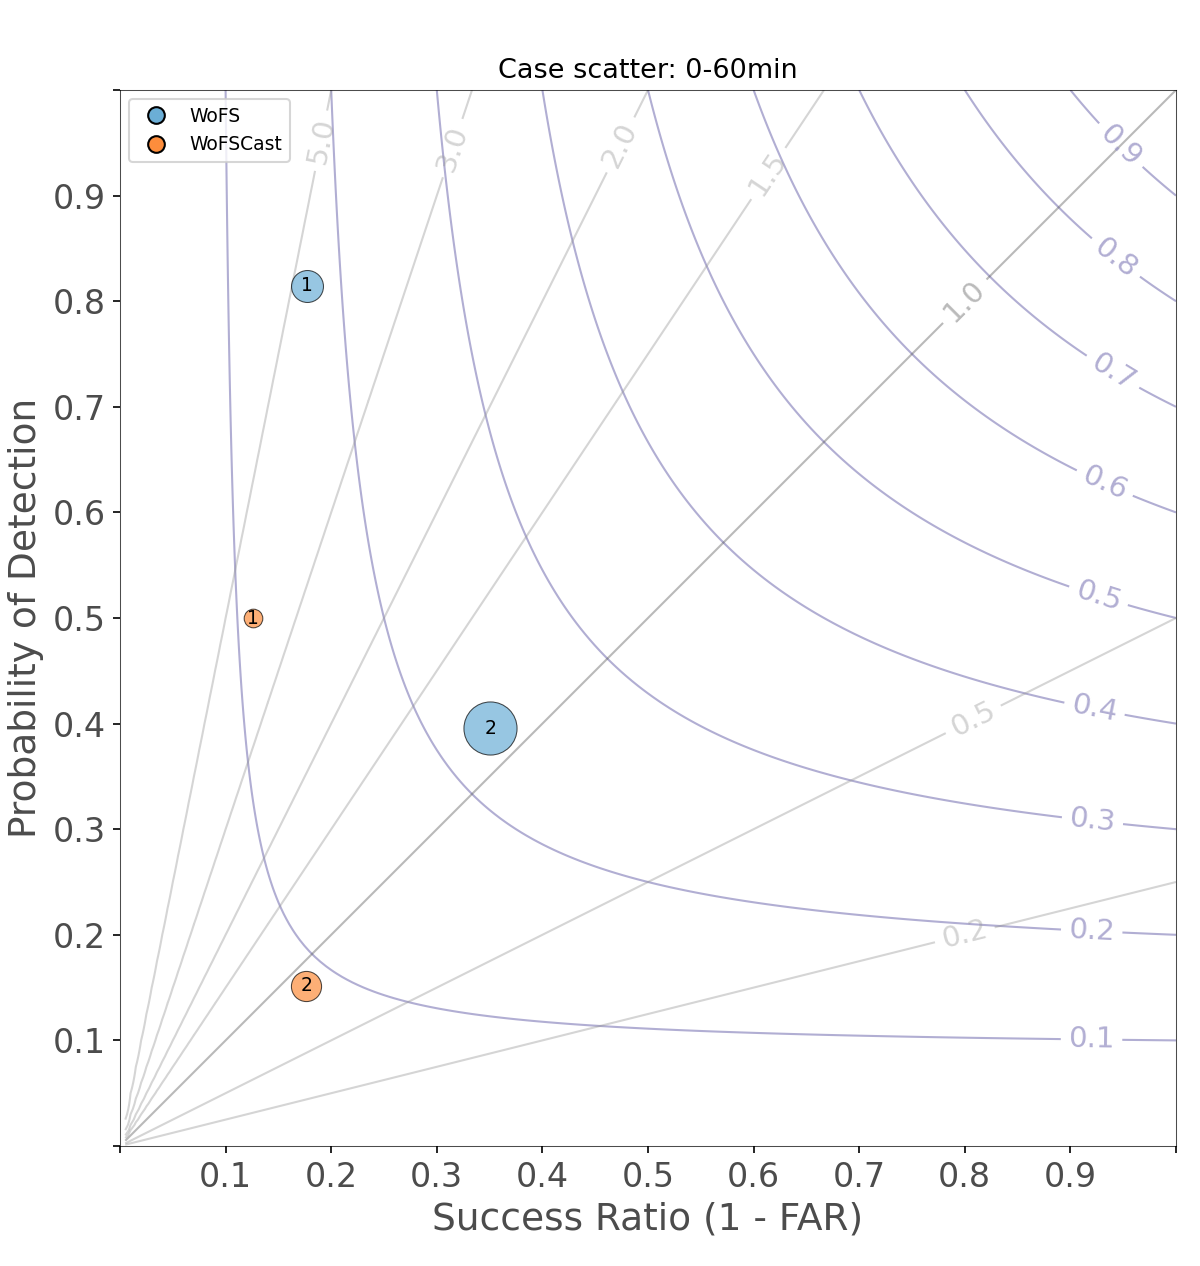

In [5]:
display(Image(filename=os.path.join(result["config"].output_dir, "case_scatter_0-60min.png")))


## Object-property POD heatmap -- truth object area

Probability of Detection as a function of both forecast lead time and the truth object's own area.


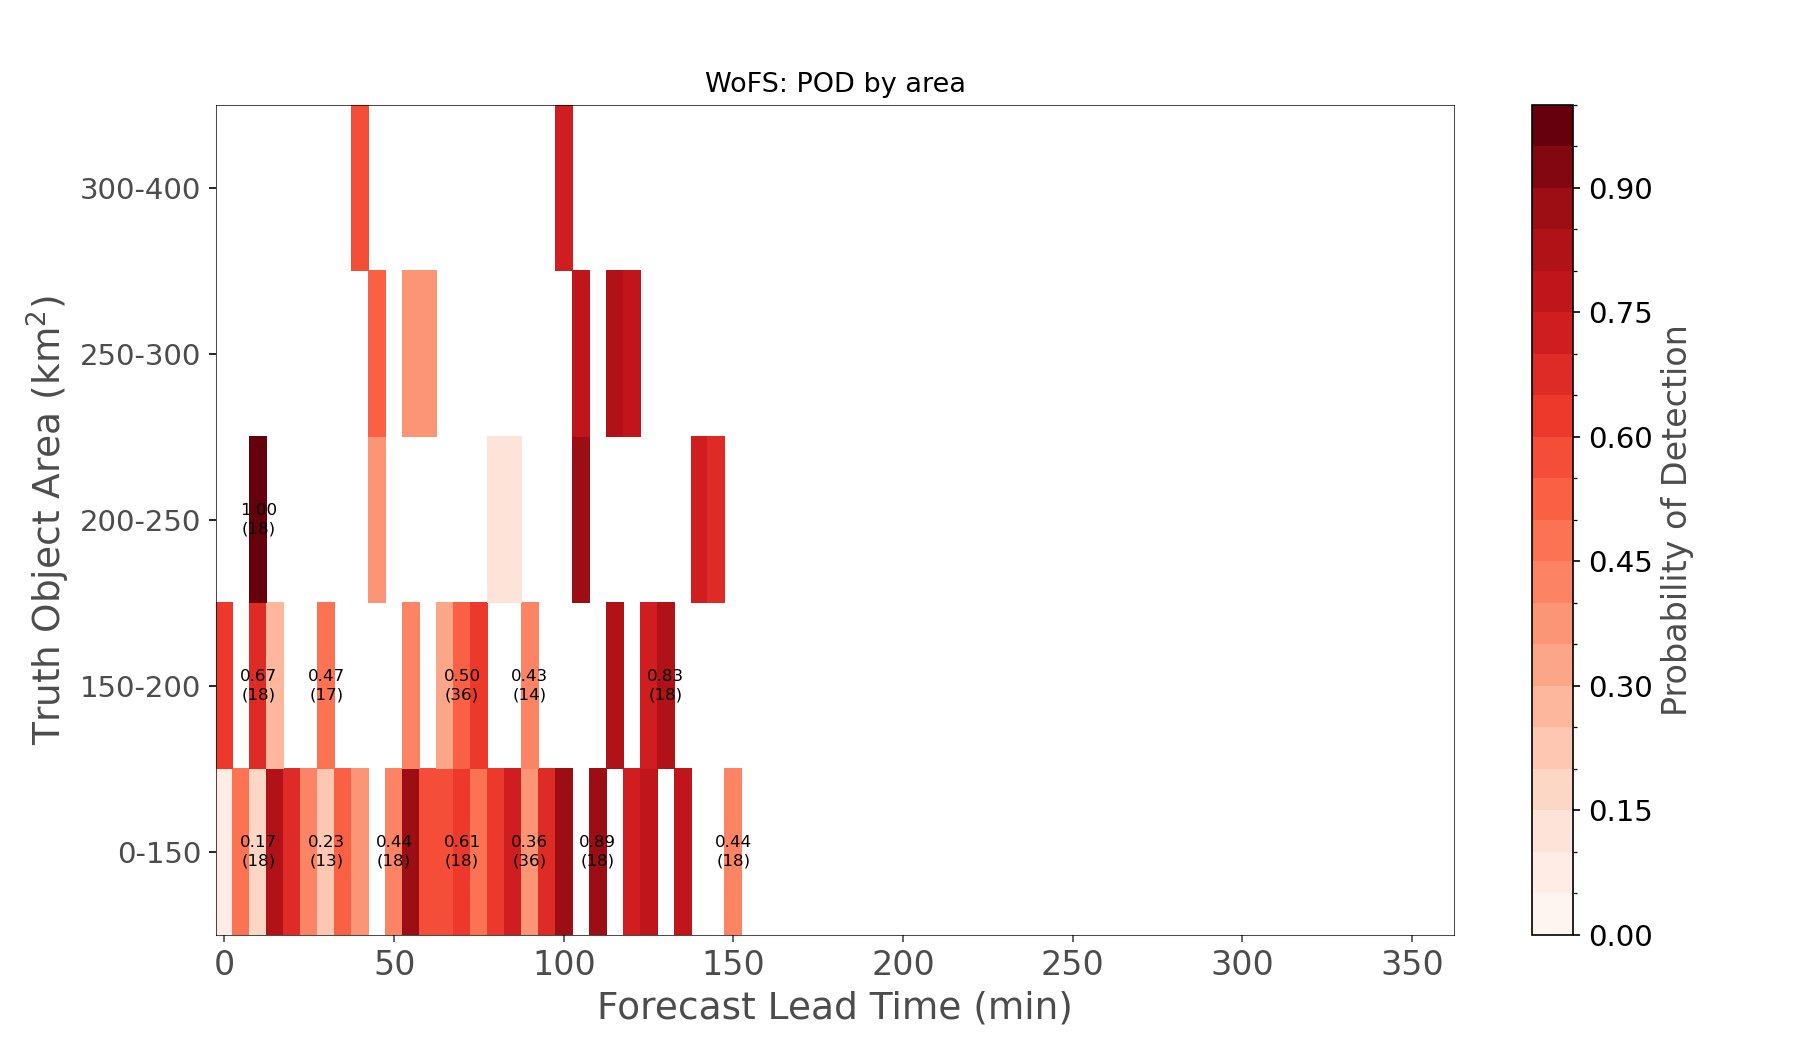

In [6]:
display(Image(filename=os.path.join(result["config"].output_dir, "heatmap_area_WoFS.png")))


## Closing

This notebook exercised every major capability of the matching-timeseries suite against a small, real, bundled 2-case slice. See `README.md` for the full list of what each section of `config_sample_wofs_wofscast_suite.yaml` controls, and `CONFIG_REFERENCE.md` for every available config field. `configs/config_sfe_wofs_vs_wofscast_suite.yaml` runs the identical suite against the much larger `sfe_poster/` archive for a statistically meaningful comparison.
